<a href="https://colab.research.google.com/github/MwangiMuriuki2003/MURIUKI/blob/main/Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install celluloid
!pip install scienceplots
!pip install ipympl
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from celluloid import Camera
import scienceplots
from IPython.display import Image

np.random.seed(0)
plt.style.use(["science", "no-latex"])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.0/519.0 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 101.9 MB/s eta 0:00:00


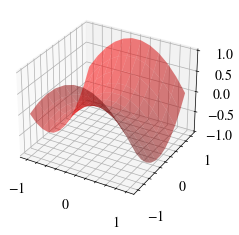

In [ ]:
def generate_function(dims):
    a = 1
    b = 1

    # Hyperbolic Paraboloid
    x = np.linspace(-1, 1, dims)
    y = np.linspace(-1, 1, dims)
    X, Y = np.meshgrid(x, y)
    Z = (Y**2 / b**2) - (X**2 / a**2)

    X_t = X.flatten()
    Y_t = Y.flatten()
    Z_t = Z.flatten()
    X_t = X_t.reshape((len(X_t), 1))
    Y_t = Y_t.reshape((len(Y_t), 1))
    Z_t = Z_t.reshape((len(Z_t), 1))
    features = np.stack((X_t, Y_t), axis=1)
    labels = Z_t.reshape((len(Z_t), 1, 1))

    return X, Y, Z, features, labels


dims = 12
X, Y, Z, features, labels = generate_function(dims)

# Visualize the Hyperbolic Paraboloid
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(X, Y, Z, color="red", alpha=0.5)

In [ ]:
def mse(y_true, y_pred):
    return np.mean(np.power(y_true - y_pred, 2))

def mse_prime(y_true, y_pred):
    return 2 * (y_pred - y_true) / np.size(y_true)

In [ ]:
from abc import ABC, abstractmethod


class Layer(ABC):
    def __init__(self):
        self.input = None
        self.output = None
        self.weights = None
        self.bias = None

    @abstractmethod
    def forward(self, input):
        pass

    @abstractmethod
    def backward(self, output_gradient, optimizer):
        pass

In [ ]:
class Dense(Layer):
    def __init__(self, input_neurons, output_neurons):
        # Random Values from Normal Distribution
        # self.weights = np.random.randn(output_neurons, input_neurons)
        # self.bias = np.random.randn(output_neurons, 1)

        # All Zeros
        # self.weights = np.zeros((output_neurons, input_neurons))
        # self.bias = np.zeros((output_neurons, 1))

        # Xavier Initialization Uniform Distribution
        limit = np.sqrt(6 / (input_neurons + output_neurons))
        self.weights = np.random.uniform(
            -limit, limit, size=(output_neurons, input_neurons)
        )
        self.bias = np.zeros((output_neurons, 1))

    def forward(self, input):
        self.input = input
        return np.matmul(self.weights, self.input) + self.bias

    def backward(self, output_gradient, optimizer):
        # Calculate gradients
        weights_gradient = np.matmul(output_gradient, self.input.T)
        input_gradient = np.dot(self.weights.T, output_gradient)

        # Update weights and biases
        self.weights, self.bias = optimizer.backward(
            self.weights, weights_gradient, self.bias, output_gradient
        )
        return input_gradient

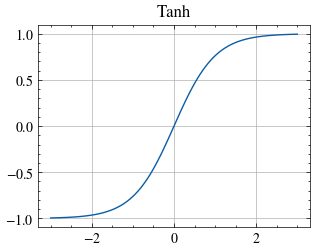

In [ ]:
class Activation(Layer):
    def __init__(self, activation, activation_prime):
        super().__init__()
        self.activation = activation
        self.activation_prime = activation_prime

    def forward(self, input):
        self.input = input
        return self.activation(self.input)

    def backward(self, output_gradient, optimizer):
        return output_gradient * self.activation_prime(self.input)

    def plot(self, start, end):
        x = np.linspace(start, end, 100)
        y = self.activation(x)
        plt.figure()
        plt.plot(x, y)
        plt.title(self.__class__.__name__)
        plt.grid(True)
        plt.show()

class Tanh(Activation):
    def __init__(self):
        tanh = lambda x: np.tanh(x)
        tanh_prime = lambda x: 1 - np.tanh(x) ** 2
        super().__init__(tanh, tanh_prime)


Tanh().plot(-3, 3)

In [ ]:
class GradientDescentOptimizier:
    def __init__(self, learning_rate):
        self.learning_rate = learning_rate

    def backward(self, weights, weights_gradient, bias, output_gradient):
        weights -= self.learning_rate * weights_gradient
        bias -= self.learning_rate * output_gradient

        return weights, bias

In [ ]:
import copy


def create_scatter_and_3d_plot():
    fig, ax = plt.subplots(1, 3, figsize=(16 / 9.0 * 4, 4 * 1))
    fig.suptitle("Neural Network Predictions")

    ax[0].set_xlabel("Epoch", fontweight="normal")
    ax[0].set_ylabel("Error", fontweight="normal")
    ax[0].set_title("Mean Squared Error")

    ax[1].axis("off")
    ax[2].axis("off")

    ax[2] = fig.add_subplot(1, 2, 2, projection="3d")
    ax[2].set_xlabel("X")
    ax[2].set_ylabel("Y")
    ax[2].set_zlabel("Z")
    ax[2].set_title("Function Approximation")
    ax[2].view_init(20, -35)
    ax[2].set_zlim(-1, 1)
    ax[2].axis("equal")

    camera = Camera(fig)
    return ax[0], ax[2], camera


def create_3d_and_3d_plot():
    fig, ax = plt.subplots(
        1, 2, figsize=(16 / 9.0 * 4, 4 * 1), subplot_kw={"projection": "3d"}
    )
    fig.suptitle("Neural Network Loss Landscape")

    ax[0].set_xlabel("W3_1")
    ax[0].set_ylabel("W3_2")
    ax[0].set_zlabel("MSE")
    ax[0].set_title("Mean Squared Error")
    ax[0].view_init(20, -35)
    ax[0].set_zlim(-1, 1)
    ax[0].axis("equal")

    ax[1].set_xlabel("X")
    ax[1].set_ylabel("Y")
    ax[1].set_zlabel("Z")
    ax[1].set_title("Function Approximation")
    ax[1].view_init(20, -35)
    ax[1].set_zlim(-1, 1)
    ax[1].axis("equal")

    camera = Camera(fig)
    return ax[0], ax[1], camera


def plot_3d_predictions(ax, X, Y, Z, predictions, dims):
    # Plot Neural Network Function Approximation
    # Ground truth
    ground_truth_legend = ax.plot_surface(
        X, Y, Z, color="red", alpha=0.5, label="Ground Truth"
    )

    # Neural Network Predictions
    predictions_legend = ax.scatter(
        X,
        Y,
        predictions.reshape((dims, dims)),
        color="blue",
        alpha=0.2,
        label="Prediction",
    )
    ax.plot_surface(
        X,
        Y,
        predictions.reshape((dims, dims)),
        color="blue",
        alpha=0.3,
    )
    ax.legend(
        (ground_truth_legend, predictions_legend),
        ("Ground Truth", "Predictions"),
        loc="upper left",
    )


def plot_layer_loss_landscape(
    ax0,
    network,
    target_layer_idx,
    features,
    labels,
    w1_min,
    w1_max,
    w2_min,
    w2_max,
    loss_dims,
):
    # current target layer weights
    target_layer_idx = target_layer_idx % len(network)

    w1 = network[target_layer_idx].weights[0][0]
    w2 = network[target_layer_idx].weights[0][1]
    curr_error = 0
    for x, y in zip(features, labels):
        output = x
        for layer in network:
            output = layer.forward(output)

        curr_error += mse(y, output)
    curr_error /= labels.size
    ax0.scatter([w1], [w2], [curr_error], color="red", alpha=0.4)

    target_layer = copy.deepcopy(network[target_layer_idx])
    w1_range = np.linspace(w1_min, w1_max, loss_dims)
    w2_range = np.linspace(w2_min, w2_max, loss_dims)
    w1_range, w2_range = np.meshgrid(w1_range, w2_range)
    w_range = np.stack((w1_range.flatten(), w2_range.flatten()), axis=1)

    error_range = np.array([])

    for target_layer_weight in w_range:
        target_layer_weight = target_layer_weight.reshape(1, 2)
        target_layer.weights[0, :2] = target_layer_weight[0, :2]

        error = 0
        for x, y in zip(features, labels):
            output = x
            for layer_idx, layer in enumerate(network):
                if layer_idx == target_layer_idx:
                    output = target_layer.forward(output)
                else:
                    output = layer.forward(output)

            error += mse(y, output)
        error /= labels.size
        error_range = np.append(error_range, error)

    ax0.plot_surface(
        w1_range,
        w2_range,
        error_range.reshape(loss_dims, loss_dims),
        color="blue",
        alpha=0.1,
    )


def plot_mse_and_predictions(
    ax0, ax1, idx, visible_mse, mse_idx, errors, X, Y, Z, predictions, dims
):
    ax0.plot(
        mse_idx[visible_mse][: idx + 1],
        errors[visible_mse][: idx + 1],
        color="red",
        alpha=0.5,
    )

    plot_3d_predictions(ax1, X, Y, Z, predictions, dims)


def plot_loss_landscape_and_predictions(
    ax0,
    ax1,
    network,
    target_layer_idx,
    features,
    labels,
    X,
    Y,
    Z,
    predictions,
    preds_dims,
    w1_min=-5,
    w1_max=5,
    w2_min=-5,
    w2_max=5,
    loss_dims=20,
):
    plot_3d_predictions(ax1, X, Y, Z, predictions, preds_dims)
    plot_layer_loss_landscape(
        ax0,
        network,
        target_layer_idx,
        features,
        labels,
        w1_min,
        w1_max,
        w2_min,
        w2_max,
        loss_dims,
    )


def show_epoch(epoch):
    return (
        epoch < 25
        or (epoch < 25 and epoch % 2 == 0)
        or (epoch <= 100 and epoch % 10 == 0)
        or (epoch <= 500 and epoch % 25 == 0)
        or (epoch <= 1000 and epoch % 50 == 0)
        or epoch % 250 == 0
    )

In [ ]:
def fit(
    network,
    features,
    labels,
    X,
    Y,
    Z,
    preds_dims,
    epochs,
    optimizer,
    mse_plot_filename,
    loss_landscape_plot_filename,
):
    mse_idx = np.arange(1, epochs + 1)
    errors = np.full(epochs, -1)
    mse_ax, predictions_ax1, camera1 = create_scatter_and_3d_plot()
    loss_landscape_ax, predictions_ax2, camera2 = create_3d_and_3d_plot()

    network_len = len(network)

    for idx in range(epochs):
        error = 0
        predictions = np.array([])

        for x, y in zip(features, labels):
            # Forward Propagation
            output = x
            for layer in network:
                output = layer.forward(output)

            predictions = np.append(predictions, output)

            # Store Error
            # no need to convert to numpy cpu, since both are tensors on device
            error += mse(y, output)

            # Backpropagation
            grad = mse_prime(y, output)
            for layer in reversed(network):
                grad = layer.backward(grad, optimizer)

        error /= len(X)

        if show_epoch(idx):
            print(f"epoch: {idx}, MSE: {error}")

            # Plot MSE
            errors[idx] = error
            visible_mse = errors != -1
            plot_mse_and_predictions(
                mse_ax,
                predictions_ax1,
                idx,
                visible_mse,
                mse_idx,
                errors,
                X,
                Y,
                Z,
                predictions,
                preds_dims,
            )

            # plot the loss landscape of the second to last layer
            # a 3D plot can be made because it's only 2 neurons
            plot_loss_landscape_and_predictions(
                loss_landscape_ax,
                predictions_ax2,
                network,
                -2,
                features,
                labels,
                X,
                Y,
                Z,
                predictions,
                preds_dims,
            )

            camera1.snap()
            camera2.snap()

    animation1 = camera1.animate()
    animation1.save(mse_plot_filename, writer="pillow")

    animation2 = camera2.animate()
    animation2.save(loss_landscape_plot_filename, writer="pillow")
    plt.show()

In [ ]:
model = [Dense(2, 12), Tanh(), Dense(12, 2), Tanh(), Dense(2, 1), Tanh()]

epoch: 0, MSE: 3.0033681391919598
epoch: 1, MSE: 2.861607692334731
epoch: 2, MSE: 2.8258532877372216
epoch: 3, MSE: 2.817140865761648
epoch: 4, MSE: 2.814117393067352
epoch: 5, MSE: 2.809973710893726
epoch: 6, MSE: 2.802345213761619
epoch: 7, MSE: 2.7902417103220163
epoch: 8, MSE: 2.7730636908227755
epoch: 9, MSE: 2.7502645093729328
epoch: 10, MSE: 2.721249705555072
epoch: 11, MSE: 2.6853898991971388
epoch: 12, MSE: 2.642101512218608
epoch: 13, MSE: 2.5909672804676966
epoch: 14, MSE: 2.5318693918216923
epoch: 15, MSE: 2.4651083530357476
epoch: 16, MSE: 2.3914851384273637
epoch: 17, MSE: 2.312329193512822
epoch: 18, MSE: 2.229456375261003
epoch: 19, MSE: 2.1450438173269872
epoch: 20, MSE: 2.061423945351906
epoch: 21, MSE: 1.9808288922004156
epoch: 22, MSE: 1.9051432156154482
epoch: 23, MSE: 1.8357262341875265
epoch: 24, MSE: 1.7733404220039113
epoch: 25, MSE: 1.7181844787747813
epoch: 30, MSE: 1.5333665989875438
epoch: 40, MSE: 1.3570304555393904
epoch: 50, MSE: 1.204929253830212
epoch:

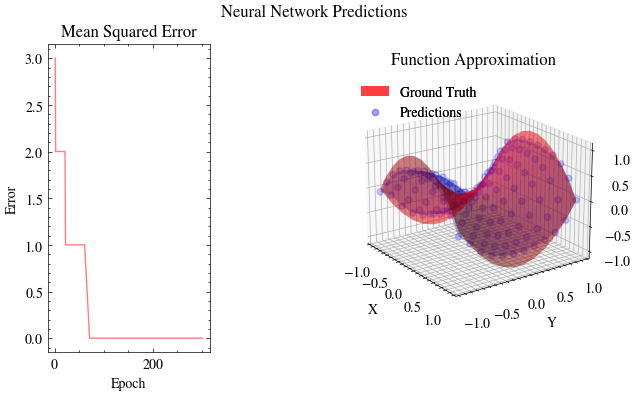

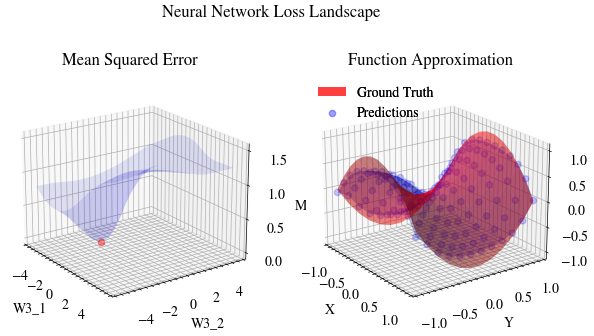

In [ ]:
epochs = 301
learning_rate = 0.005
optimizer = GradientDescentOptimizier(learning_rate)

mse_plot_filename = "neural_network.gif"
loss_landscape_plot_filename = "neural_network_loss_landscape.gif"
fit(
    model,
    features,
    labels,
    X,
    Y,
    Z,
    dims,
    epochs,
    optimizer,
    mse_plot_filename,
    loss_landscape_plot_filename,
)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)

In [ ]:
class TorchNet(nn.Module):
    def __init__(self):
        super(TorchNet, self).__init__()

        # define the layers
        self.fc1 = nn.Linear(2, 14)
        self.fc2 = nn.Linear(14, 2)
        self.fc3 = nn.Linear(2, 1)

    def forward(self, x):
        # pass the result of the previous layer to the next layer
        x = F.tanh(self.fc1(x))
        x = F.tanh(self.fc2(x))
        return F.tanh(self.fc3(x))

In [ ]:
def torch_fit(
    model, features, labels, X, Y, Z, dims, epochs, optimizer, output_filename
):
    mse_idx = np.arange(1, epochs + 1)
    errors = np.full(epochs, -1)
    mse_ax, predictions_ax1, camera1 = create_scatter_and_3d_plot()

    loss_fn = nn.MSELoss()

    for idx in range(epochs):
        error = 0
        predictions = np.array([])

        for x, y in zip(features, labels):
            # Forward Propagation
            output = model(x)

            output_np = output.detach().cpu().numpy()
            predictions = np.append(predictions, output_np)

            # Store Error
            loss = loss_fn(output, y)

            error += loss.detach().cpu().numpy()

            # Backpropagation
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        error /= len(X)

        if show_epoch(idx):
            print(f"epoch: {idx}, MSE: {error}")

            # Plot MSE
            errors[idx] = error
            visible_mse = errors != -1

            plot_mse_and_predictions(
                mse_ax,
                predictions_ax1,
                idx,
                visible_mse,
                mse_idx,
                errors,
                X,
                Y,
                Z,
                predictions,
                dims,
            )

            camera1.snap()

    animation1 = camera1.animate()
    animation1.save(output_filename, writer="pillow")
    plt.show()

epoch: 0, MSE: 2.984565496444702
epoch: 1, MSE: 2.7075679302215576
epoch: 2, MSE: 2.6843481063842773
epoch: 3, MSE: 2.6776466369628906
epoch: 4, MSE: 2.681764841079712
epoch: 5, MSE: 2.690561056137085
epoch: 6, MSE: 2.7000503540039062
epoch: 7, MSE: 2.7078511714935303
epoch: 8, MSE: 2.7127304077148438
epoch: 9, MSE: 2.7142038345336914
epoch: 10, MSE: 2.7122199535369873
epoch: 11, MSE: 2.7069084644317627
epoch: 12, MSE: 2.6984355449676514
epoch: 13, MSE: 2.686903715133667
epoch: 14, MSE: 2.672307014465332
epoch: 15, MSE: 2.6544973850250244
epoch: 16, MSE: 2.633166551589966
epoch: 17, MSE: 2.607834577560425
epoch: 18, MSE: 2.5778286457061768
epoch: 19, MSE: 2.542280435562134
epoch: 20, MSE: 2.500131607055664
epoch: 21, MSE: 2.4501826763153076
epoch: 22, MSE: 2.3912036418914795
epoch: 23, MSE: 2.3221089839935303
epoch: 24, MSE: 2.242227792739868
epoch: 25, MSE: 2.1515371799468994
epoch: 30, MSE: 1.578006386756897
epoch: 40, MSE: 0.45027267932891846
epoch: 50, MSE: 0.15558330714702606
epoc

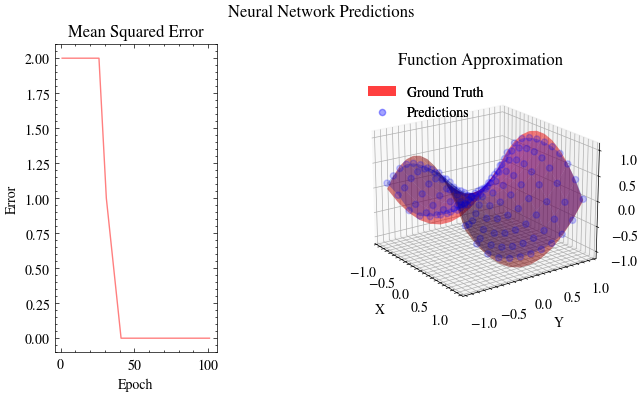

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
torch_model = TorchNet().to(device)

# the inputs and outputs for PyTorch must be tensors
features_tensor = torch.tensor(features, device=device, dtype=torch.float32).squeeze(-1)
labels_tensor = torch.tensor(labels, device=device, dtype=torch.float32).squeeze(-1)

epochs = 101
learning_rate = 0.005
optimizer = torch.optim.SGD(torch_model.parameters(), lr=learning_rate, momentum=0.0)

output_filename_pytorch = "neural_network_pytorch.gif"
torch_fit(
    torch_model,
    features_tensor,
    labels_tensor,
    X,
    Y,
    Z,
    dims,
    epochs,
    optimizer,
    output_filename_pytorch,
)

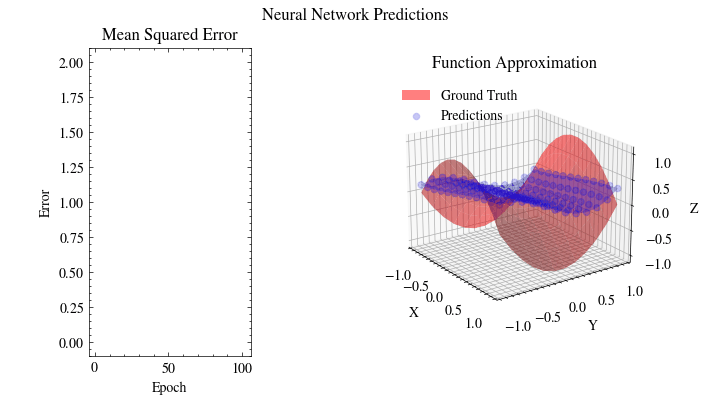

In [16]:
Image(filename=output_filename_pytorch)